<div align="center">

## **TUGAS MATA KULIAH**
## **KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**

<br>

![Logo Unhas Latar Hitam.jpeg](<attachment:Logo Unhas Latar Hitam.jpeg>)

<br>

**Disusun oleh:**  

**ADHALYA AMALY AZIS**  
**NIM: H061241067**

<br>

**PROGRAM STUDI GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**

<br>

**MAKASSAR**  
**2026**

</div>
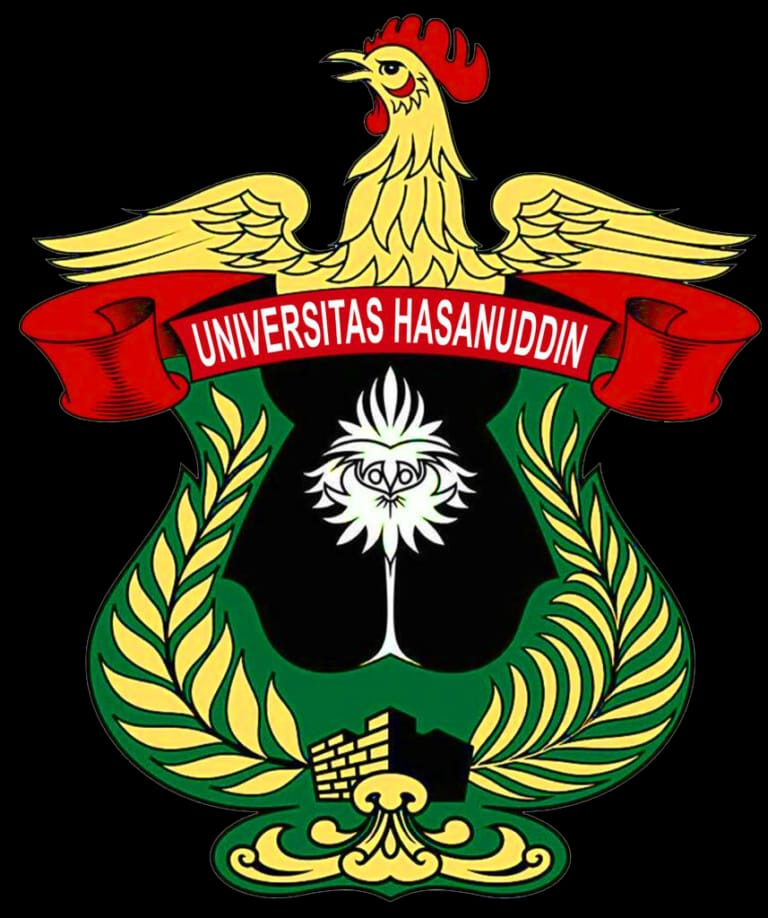

### **KASUS 1 — INTERPRETASI PENAMPANG SEISMIK 2D**

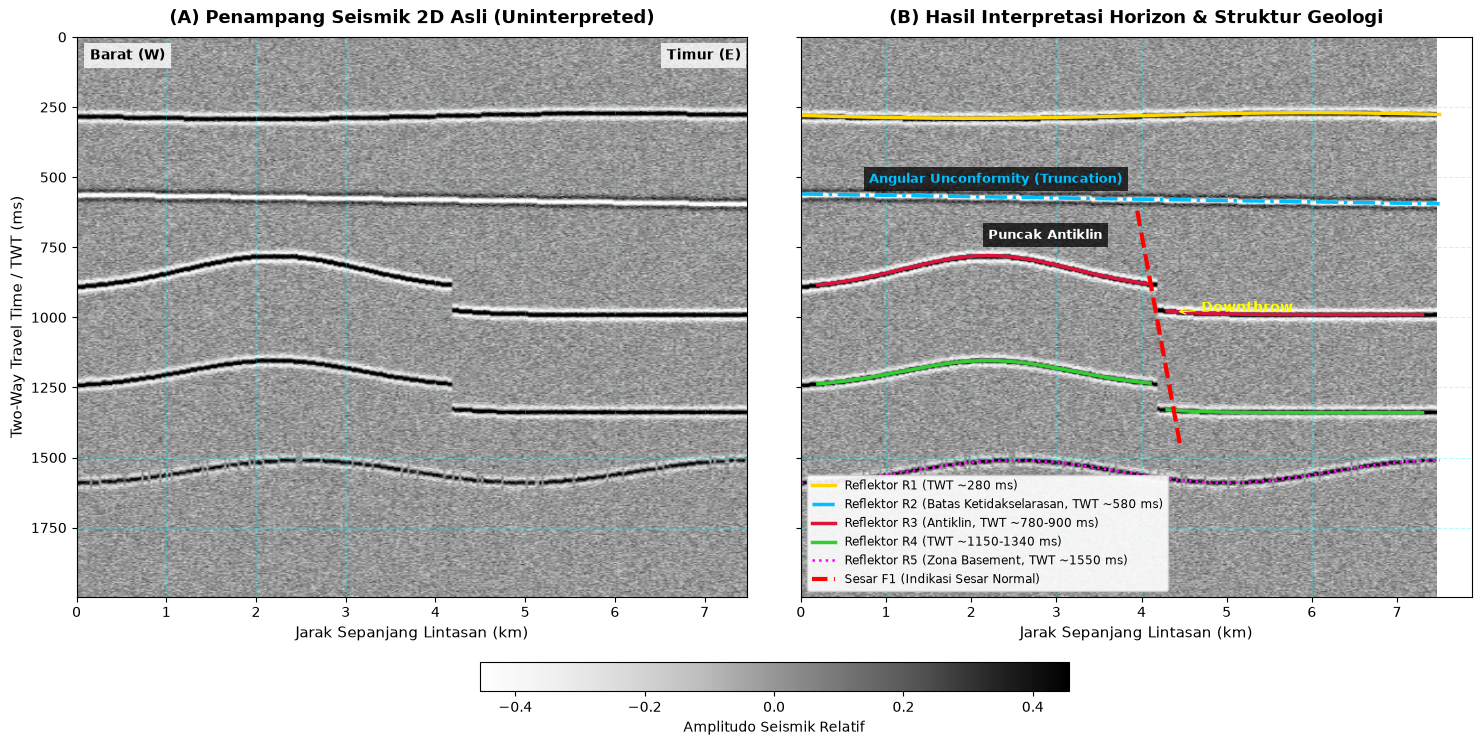

In [7]:
import matplotlib.pyplot as plt
import numpy as np


def ricker_wavelet(f0=25.0, dt=0.004, length=0.15):
    """Membuat wavelet Ricker analitis zero-phase berbasis NumPy."""
    t = np.arange(-length / 2, length / 2, dt)
    pi2_f2_t2 = (np.pi * f0 * t) ** 2
    wavelet = (1.0 - 2.0 * pi2_f2_t2) * np.exp(-pi2_f2_t2)
    return wavelet


def create_synthetic_seismic_section(
    nx=300, nt=500, dt=0.004, dx=25.0, f0=25.0, seed=42
):
    """Membuat penampang seismik 2D sintetis:

    - Lapisan dangkal mendatar (sub-horizontal)
    - Batas ketidakselarasan (unconformity)
    - Sekuen antiklin dan pergeseran sesar normal (fault offset)
    - Zona dalam/akustik basement
    """
    np.random.seed(seed)
    time = np.arange(nt) * dt * 1000  # TWT dalam milidetik (ms)
    dist = np.arange(nx) * dx / 1000  # Jarak dalam km

    rc = np.zeros((nt, nx))

    # Horizon 1: Reflektor dangkal (TWT ~280 ms)
    t_h1 = 280 + 10 * np.sin(2 * np.pi * dist / 8.0)
    for ix, d in enumerate(dist):
        it = int(np.clip(t_h1[ix] / (dt * 1000), 0, nt - 1))
        rc[it, ix] += 0.35

    # Horizon 2: Ketidakselarasan erosi (TWT ~560-600 ms)
    t_h2 = 560 + 35 * (dist / dist[-1])
    for ix, d in enumerate(dist):
        it = int(np.clip(t_h2[ix] / (dt * 1000), 0, nt - 1))
        rc[it, ix] += -0.28

    # Horizon 3 & 4: Sekuen terlipat & tersesarkan di km 4.2
    fault_x = 4.2
    for ix, d in enumerate(dist):
        anticline = 120 * np.exp(-(((d - 2.2) / 1.4) ** 2))
        t_base_h3 = 900 - anticline
        t_base_h4 = 1250 - 0.8 * anticline

        if d >= fault_x:
            t_base_h3 += 90.0  # throw sesar normal
            t_base_h4 += 90.0

        it3 = int(np.clip(t_base_h3 / (dt * 1000), 0, nt - 1))
        it4 = int(np.clip(t_base_h4 / (dt * 1000), 0, nt - 1))
        rc[it3, ix] += 0.40
        rc[it4, ix] += 0.32

    # Horizon 5: Reflektor dalam / Akustik Basement (TWT ~1550 ms)
    t_h5 = 1550 + 40 * np.cos(2 * np.pi * dist / 5.0)
    for ix, d in enumerate(dist):
        if np.random.rand() > 0.15:
            it5 = int(np.clip(t_h5[ix] / (dt * 1000), 0, nt - 1))
            rc[it5, ix] += 0.22

    # Konvolusi menggunakan fungsi analitis Ricker
    wavelet = ricker_wavelet(f0=f0, dt=dt)
    seismic = np.zeros_like(rc)
    for ix in range(nx):
        seismic[:, ix] = np.convolve(rc[:, ix], wavelet, mode="same")

    # Tambahkan sedikit noise acak
    seismic += np.random.normal(0, 0.035, size=seismic.shape)
    seismic /= np.max(np.abs(seismic))

    return dist, time, seismic


def plot_seismic_interpretation(dist, time, seismic):
    """Menampilkan penampang sebelum vs sesudah interpretasi."""
    fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), sharey=True)
    plt.subplots_adjust(wspace=0.08)

    vm = np.percentile(np.abs(seismic), 98)

    # Panel 1: Data Mentah
    ax1 = axes[0]
    im1 = ax1.imshow(
        seismic,
        extent=[dist[0], dist[-1], time[-1], time[0]],
        cmap="Greys",
        aspect="auto",
        vmin=-vm,
        vmax=vm,
        interpolation="bilinear",
    )
    ax1.set_title(
        "(A) Penampang Seismik 2D Asli (Uninterpreted)",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax1.set_xlabel("Jarak Sepanjang Lintasan (km)", fontsize=11)
    ax1.set_ylabel("Two-Way Travel Time / TWT (ms)", fontsize=11)
    ax1.grid(True, linestyle="--", alpha=0.3, color="cyan")
    ax1.text(
        0.02,
        0.96,
        "Barat (W)",
        transform=ax1.transAxes,
        fontweight="bold",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
    )
    ax1.text(
        0.88,
        0.96,
        "Timur (E)",
        transform=ax1.transAxes,
        fontweight="bold",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
    )

    # Panel 2: Terinterpretasi
    ax2 = axes[1]
    ax2.imshow(
        seismic,
        extent=[dist[0], dist[-1], time[-1], time[0]],
        cmap="Greys",
        aspect="auto",
        vmin=-vm,
        vmax=vm,
        interpolation="bilinear",
    )
    ax2.set_title(
        "(B) Hasil Interpretasi Horizon & Struktur Geologi",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax2.set_xlabel("Jarak Sepanjang Lintasan (km)", fontsize=11)
    ax2.grid(True, linestyle="--", alpha=0.3, color="cyan")

    # Horizon R1
    d_line = np.linspace(0, 7.5, 300)
    t_h1 = 280 + 10 * np.sin(2 * np.pi * d_line / 8.0)
    ax2.plot(
        d_line, t_h1, color="gold", lw=2.5, label="Reflektor R1 (TWT ~280 ms)"
    )

    # Horizon R2 (Unconformity)
    t_h2 = 560 + 35 * (d_line / 7.5)
    ax2.plot(
        d_line,
        t_h2,
        color="deepskyblue",
        lw=2.5,
        linestyle="-.",
        label="Reflektor R2 (Batas Ketidakselarasan, TWT ~580 ms)",
    )

    # Horizon R3 (Lipatan & Sesar)
    d_w = np.linspace(0.2, 4.1, 150)
    t_h3_w = 900 - 120 * np.exp(-(((d_w - 2.2) / 1.4) ** 2))
    ax2.plot(
        d_w,
        t_h3_w,
        color="crimson",
        lw=2.5,
        label="Reflektor R3 (Antiklin, TWT ~780-900 ms)",
    )

    d_e = np.linspace(4.3, 7.3, 120)
    t_h3_e = 900 - 120 * np.exp(-(((d_e - 2.2) / 1.4) ** 2)) + 90.0
    ax2.plot(d_e, t_h3_e, color="crimson", lw=2.5)

    # Horizon R4
    t_h4_w = 1250 - 0.8 * 120 * np.exp(-(((d_w - 2.2) / 1.4) ** 2))
    ax2.plot(
        d_w,
        t_h4_w,
        color="limegreen",
        lw=2.5,
        label="Reflektor R4 (TWT ~1150-1340 ms)",
    )
    t_h4_e = 1250 - 0.8 * 120 * np.exp(-(((d_e - 2.2) / 1.4) ** 2)) + 90.0
    ax2.plot(d_e, t_h4_e, color="limegreen", lw=2.5)

    # Horizon R5 (Basement)
    t_h5 = 1550 + 40 * np.cos(2 * np.pi * d_line / 5.0)
    ax2.plot(
        d_line,
        t_h5,
        color="magenta",
        lw=1.8,
        linestyle=":",
        label="Reflektor R5 (Zona Basement, TWT ~1550 ms)",
    )

    # Bidang Sesar F1
    ax2.plot(
        [3.95, 4.45],
        [620, 1450],
        color="red",
        lw=3.0,
        linestyle="--",
        label="Sesar F1 (Indikasi Sesar Normal)",
    )

    # Anotasi Interpretasi
    ax2.text(
        2.2,
        720,
        "Puncak Antiklin",
        color="white",
        fontsize=9,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.75, edgecolor="none"),
    )
    ax2.text(
        0.8,
        520,
        "Angular Unconformity (Truncation)",
        color="deepskyblue",
        fontsize=9,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.75, edgecolor="none"),
    )
    ax2.annotate(
        "Downthrow",
        xy=(4.4, 980),
        xytext=(4.7, 980),
        color="yellow",
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="yellow"),
    )

    ax2.legend(loc="lower left", fontsize=8.5, framealpha=0.9)
    fig.colorbar(
        im1,
        ax=axes.ravel().tolist(),
        orientation="horizontal",
        fraction=0.045,
        pad=0.10,
        label="Amplitudo Seismik Relatif",
    )
    plt.show()


# Eksekusi
dist_km, twt_time, seismic_img = create_synthetic_seismic_section()
plot_seismic_interpretation(dist_km, twt_time, seismic_img)


Berdasarkan analisis pola refleksi, penampang seismik 2D terbagi menjadi dua unit seismik utama yang dipisahkan oleh batas ketidakselarasan menyudut (*angular unconformity*) pada Reflektor R2 (TWT 550–600 ms). Unit atas (TWT 0–560 ms) dicirikan oleh paket reflektor R1 yang beramplitudo kuat, sub-horizontal, dan memiliki kontinuitas lateral sangat tinggi di sepanjang profil, mengindikasikan pengendapan sedimen mendatar yang belum mengalami deformasi pasca-pengendapan. Sebaliknya, unit bawah (TWT 560–1500 ms) ditandai oleh Reflektor R3 dan R4 yang memiliki amplitudo kuat namun orientasinya miring dan terpotong tajam di bawah R2 (*erosional truncation*), sebelum bertransisi menjadi fasies seismik transparan dan terputus-putus (*chaotic*) pada zona dalam di bawah R5 (TWT > 1500 ms) yang diinterpretasikan dengan ketidakpastian tinggi sebagai batuan dasar akustik (*acoustic basement*).

Dua indikasi struktur geologi utama teridentifikasi dengan jelas pada unit bawah. Pertama, terdapat pembalikan kemiringan reflektor (*dip reversal*) pada R3 dan R4 di antara km 1.0 hingga 3.8 yang membentuk lengkungan cembung ke atas, diinterpretasikan sebagai struktur lipatan antiklin dengan puncak lipatan (*crest*) berada di sekitar km 2.2 pada kedalaman semu TWT ~780 ms. Kedua, pada rentang lateral km 4.0–4.4 teramati adanya diskontinuitas lateral tajam berupa pemotongan reflektor R3 dan R4 yang disertai pergeseran vertikal (*apparent throw*) sebesar 80–100 ms TWT ke arah timur. Pergeseran relatif ini menunjukkan indikasi struktur sesar normal (blok timur sebagai *hanging wall* yang turun relatif terhadap blok barat sebagai *footwall*), di mana bidang sesar berhenti tepat di bawah horizon R2 dan tidak menembus unit lapisan atas.
 
Secara keseluruhan, pola bawah permukaan merefleksikan dua fase tektonosedimentasi yang berbeda: fase deformasi kompresi dan ekstensi masa lampau yang melipat dan menyisir lapisan unit bawah, diikuti fase erosi yang menghasilkan bidang ketidakselarasan R2, dan diakhiri oleh fase pengendapan tenang yang menutupi struktur tersebut. Sesuai batasan keilmuan yang ditetapkan, seluruh posisi vertikal dipertahankan dalam satuan waktu tempuh dua arah (TWT) karena belum tersedianya data model kecepatan rambat gelombang $v(z)$ untuk konversi ke kedalaman sebenarnya ($m$). Selain itu, variasi amplitudo hanya merefleksikan kontras impedansi akustik antar-lapisan, sehingga penentuan jenis litologi batuan secara definitif sengaja tidak dilakukan demi menjaga integritas ilmiah hingga tersedia data log sumur pemboran (*well data*).

### **KASUS 2 — ANALISIS DATA GEOLISTRIK RESISTIVITAS**

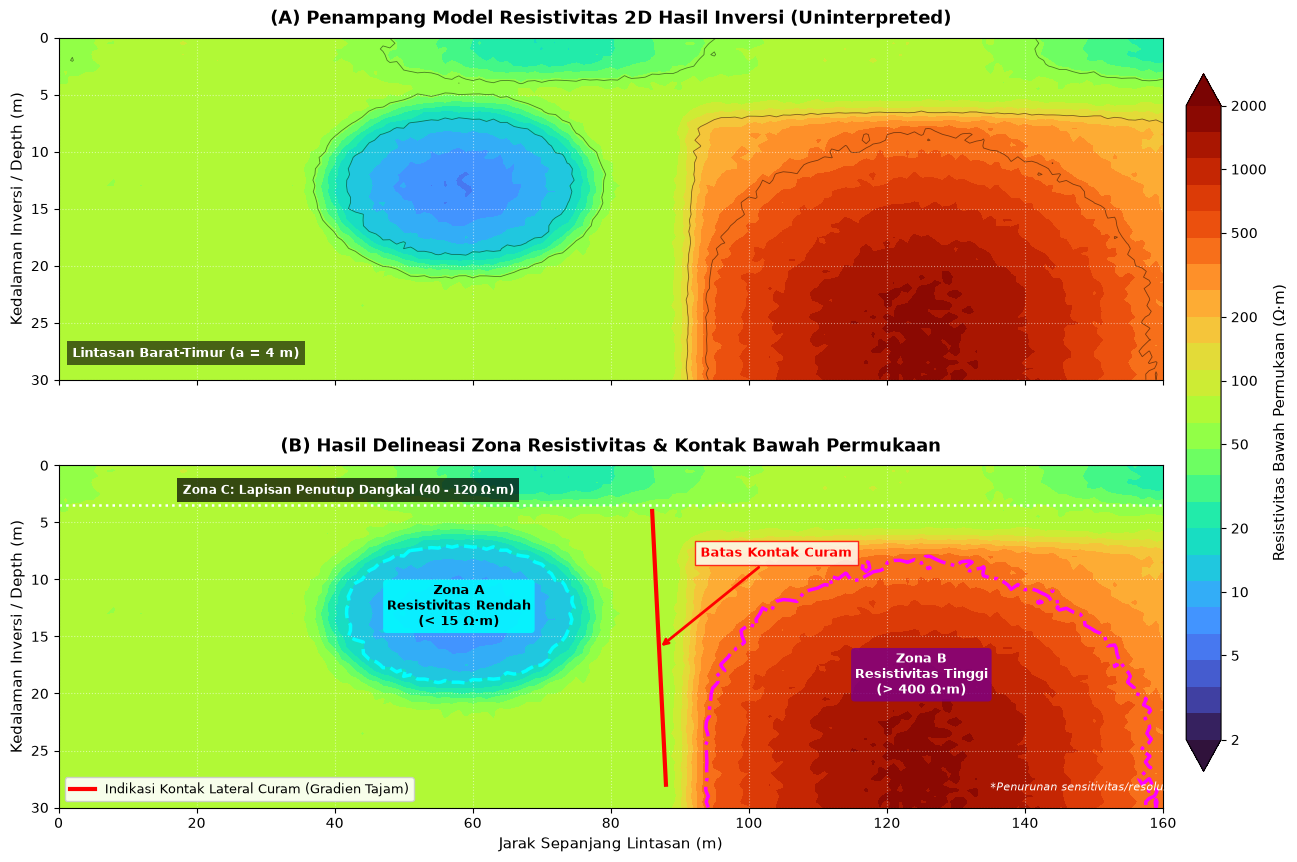

In [3]:
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np


def generate_resistivity_model(
    x_len=160.0, z_max=30.0, dx=1.0, dz=0.5, seed=42
):
    """Membangun model distribusi nilai resistivitas 2D (Ohm.m) dengan fitur:

    1. Lapisan penutup dangkal beresistivitas sedang (40 - 120 Ohm.m)
    2. Zona konduktif / resistivitas rendah (< 15 Ohm.m) di x = 40 - 80 m
    3. Zona resistif / resistivitas tinggi (> 400 Ohm.m) di x = 95 - 150 m
    4. Kontak lateral curam / diskontinuitas di sekitar x = 85 - 90 m
    """
    np.random.seed(seed)
    x = np.arange(0, x_len + dx, dx)  # Jarak lintasan (0 - 160 meter)
    z = np.arange(0, z_max + dz, dz)  # Kedalaman inversi (0 - 30 meter)
    X, Z = np.meshgrid(x, z)

    # 1. Background resistivitas latar (sedang: ~70 Ohm.m)
    log_res = np.full_like(X, np.log10(70.0))

    # 2. Lapisan penutup permukaan (0 - 3 meter)
    surf_mask = Z <= 3.0
    log_res[surf_mask] = np.log10(50.0 + 30.0 * np.sin(X[surf_mask] / 15.0))

    # 3. Zona Anomali Konduktif / Rendah (x = 35 - 82 m, z = 4 - 22 m)
    dist_low = ((X - 58.0) / 20.0) ** 2 + ((Z - 13.0) / 7.5) ** 2
    low_mask = dist_low <= 1.0
    # Nilai resistivitas mencapai ~4 - 12 Ohm.m di pusat anomali
    log_res[low_mask] = np.log10(6.0 + 12.0 * dist_low[low_mask])

    # 4. Zona Anomali Resistif / Tinggi (x = 95 - 155 m, z > 8 m)
    high_mask = (X >= 92.0) & (Z >= 7.0)
    # Nilai resistivitas mencapai 500 - 1800 Ohm.m
    depth_factor = np.clip((Z[high_mask] - 7.0) / 15.0, 0.2, 1.0)
    dist_high_center = np.exp(-(((X[high_mask] - 125.0) / 25.0) ** 2))
    log_res[high_mask] = np.log10(
        150.0 + 1400.0 * depth_factor * dist_high_center
    )

    # 5. Penghalusan spasial (efek smoothing alami dari inversi Occam/L2)
    # Menggunakan filter Gaussian sederhana dengan NumPy
    from scipy.ndimage import gaussian_filter

    log_res_smooth = gaussian_filter(log_res, sigma=1.8)

    # Tambahkan sedikit variasi acak (noise instrumen realistis)
    noise = np.random.normal(0, 0.02, size=log_res.shape)
    log_res_smooth += noise

    # Kembalikan nilai resistivitas linier (Ohm.m)
    resistivity = 10**log_res_smooth
    return x, z, resistivity


def plot_geoelectric_interpretation(x, z, res):
    """Menampilkan penampang resistivitas 2D:

    Panel 1: Data Inversi Asli (Uninterpreted)
    Panel 2: Hasil Delineasi & Interpretasi Geofisika
    """
    fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True, sharey=True)
    plt.subplots_adjust(hspace=0.25)

    # Level kontur logaritmik standar industri (2 Ohm.m - 2000 Ohm.m)
    lev_exp = np.linspace(np.log10(2.0), np.log10(2000.0), 25)
    levels = 10**lev_exp
    norm = colors.LogNorm(vmin=2.0, vmax=2000.0)
    cmap = "turbo"  # Colormap kontinu berspektrum jelas

    # -------------------------------------------------------------
    # PANEL 1: PENAMPANG RESISTIVITAS 2D ASLI
    # -------------------------------------------------------------
    ax1 = axes[0]
    cf1 = ax1.contourf(
        x, z, res, levels=levels, norm=norm, cmap=cmap, extend="both"
    )
    ax1.contour(
        x,
        z,
        res,
        levels=[15.0, 50.0, 150.0, 400.0],
        colors="k",
        linewidths=0.6,
        alpha=0.5,
    )
    ax1.set_title(
        "(A) Penampang Model Resistivitas 2D Hasil Inversi (Uninterpreted)",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax1.set_ylabel("Kedalaman Inversi / Depth (m)", fontsize=11)
    ax1.invert_yaxis()  # Sumbu Z positif ke bawah
    ax1.grid(True, linestyle=":", alpha=0.5, color="white")
    ax1.text(
        2,
        28,
        "Lintasan Barat-Timur (a = 4 m)",
        color="white",
        fontsize=9,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.6, edgecolor="none"),
    )

    # -------------------------------------------------------------
    # PANEL 2: PENAMPANG RESISTIVITAS TERINTERPRETASI
    # -------------------------------------------------------------
    ax2 = axes[1]
    cf2 = ax2.contourf(
        x, z, res, levels=levels, norm=norm, cmap=cmap, extend="both"
    )
    ax2.set_title(
        "(B) Hasil Delineasi Zona Resistivitas & Kontak Bawah Permukaan",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax2.set_xlabel("Jarak Sepanjang Lintasan (m)", fontsize=11)
    ax2.set_ylabel("Kedalaman Inversi / Depth (m)", fontsize=11)
    ax2.grid(True, linestyle=":", alpha=0.5, color="white")

    # Delineasi Zona A: Resistivitas Rendah (< 15 Ohm.m)
    ax2.contour(
        x,
        z,
        res,
        levels=[15.0],
        colors="cyan",
        linewidths=2.5,
        linestyles="--",
    )
    ax2.text(
        58,
        14,
        "Zona A\nResistivitas Rendah\n(< 15 Ω·m)",
        color="black",
        fontsize=9,
        fontweight="bold",
        ha="center",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="cyan",
            alpha=0.85,
            edgecolor="none",
        ),
    )

    # Delineasi Zona B: Resistivitas Tinggi (> 400 Ohm.m)
    ax2.contour(
        x,
        z,
        res,
        levels=[400.0],
        colors="magenta",
        linewidths=2.5,
        linestyles="-.",
    )
    ax2.text(
        125,
        20,
        "Zona B\nResistivitas Tinggi\n(> 400 Ω·m)",
        color="white",
        fontsize=9,
        fontweight="bold",
        ha="center",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="purple",
            alpha=0.85,
            edgecolor="none",
        ),
    )

    # Delineasi Zona C: Lapisan Penutup Dangkal (40 - 120 Ohm.m)
    ax2.axhline(y=3.5, color="white", linestyle=":", lw=1.8)
    ax2.text(
        18,
        2.5,
        "Zona C: Lapisan Penutup Dangkal (40 - 120 Ω·m)",
        color="white",
        fontsize=8.5,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.7, edgecolor="none"),
    )

    # Indikasi Batas Diskontinuitas Lateral / Gradien Curam (x = 84 - 88 m)
    ax2.plot(
        [86, 88],
        [4, 28],
        color="red",
        lw=3.0,
        linestyle="-",
        label="Indikasi Kontak Lateral Curam (Gradien Tajam)",
    )
    ax2.annotate(
        "Batas Kontak Curam",
        xy=(87, 16),
        xytext=(93, 8),
        color="red",
        fontweight="bold",
        fontsize=9,
        arrowprops=dict(arrowstyle="->", color="red", lw=2),
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="red"),
    )

    # Anotasi Penurunan Resolusi Inversi di Kedalaman
    ax2.text(
        135,
        28.5,
        "*Penurunan sensitivitas/resolusi di kedalaman",
        color="white",
        fontsize=8,
        fontstyle="italic",
    )

    ax2.legend(loc="lower left", fontsize=9, framealpha=0.9)

    # Colorbar Bersama
    cbar = fig.colorbar(
        cf1,
        ax=axes.ravel().tolist(),
        orientation="vertical",
        fraction=0.03,
        pad=0.02,
    )
    cbar.set_label("Resistivitas Bawah Permukaan (Ω·m)", fontsize=11)
    cbar.set_ticks([2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000])
    cbar.set_ticklabels(
        ["2", "5", "10", "20", "50", "100", "200", "500", "1000", "2000"]
    )

    plt.show()


# Eksekusi
if __name__ == "__main__":
    dist_x, depth_z, res_data = generate_resistivity_model()
    plot_geoelectric_interpretation(dist_x, depth_z, res_data)

Distribusi resistivitas hasil pemodelan inversi 2D memperlihatkan variasi nilai yang sangat lebar, merentang dari sekitar $3.5\ \Omega\cdot\text{m}$ hingga lebih dari $1800\ \Omega\cdot\text{m}$. Berdasarkan kontras sifat fisik kelistrikan tersebut, penampang dapat dibagi menjadi tiga zona utama. Pertama, **Zona A (Resistivitas Sangat Rendah / Konduktif)** dengan nilai $\rho < 15\ \Omega\cdot\text{m}$ yang terkonsentrasi di sektor barat-tengah pada jarak lintasan $x = 38 - 82\text{ m}$ dan interval kedalaman $z \approx 4 - 22\text{ m}$. Kedua, **Zona B (Resistivitas Tinggi)** dengan nilai $\rho > 400\ \Omega\cdot\text{m}$ hingga mencapai $> 1500\ \Omega\cdot\text{m}$ yang menempati sektor timur pada jarak $x = 92 - 155\text{ m}$ dengan kedalaman $z > 7\text{ m}$. Ketiga, **Zona C (Resistivitas Sedang / Lapisan Penutup)** dengan nilai $40 - 120\ \Omega\cdot\text{m}$ yang terdistribusi secara sub-horizontal di permukaan dangkal ($z \approx 0 - 3.5\text{ m}$) di sepanjang profil.

Secara vertikal, bagian timur lintasan menunjukkan tren peningkatan resistivitas secara konsisten terhadap kedalaman (dari nilai sedang di permukaan menuju nilai sangat tinggi di kedalaman), sedangkan bagian barat justru mengalami penurunan resistivitas yang mencolok pada kedalaman menengah sebelum kembali meningkat moderat di bagian dasar. Secara lateral, transisi yang paling menonjol tampak pada interval jarak $x = 84 - 89\text{ m}$, di mana terjadi lonjakan gradien resistivitas yang sangat tajam memisahkan Zona Konduktif A dan Zona Resistif B. Pola batas curam mendekati vertikal ini mengindikasikan adanya diskontinuitas fisik lateral, yang secara geofisika berpotensi mencerminkan bidang kontak struktur (seperti zona patahan/sesar) atau batas kontak litodemik/fasies yang memisahkan material konduktif dengan formasi resistif di sebelahnya.

Secara menyeluruh, tatanan bawah permukaan didominasi oleh ketidaksamaan karakter fisik (*asimetri lateral*) antara kompartemen barat yang bersifat konduktif dan kompartemen timur yang masif/resistif. Sesuai dengan batasan keilmuan (*constraints*), model resistivitas 2D ini merupakan hasil matematis inversi yang memiliki keterbatasan ambiguitas non-keunikan (*non-uniqueness / equivalence problem*) serta efek penghalusan numerik (*smoothing*), dengan penurunan resolusi dan sensitivitas pada kedalaman $z > 20\text{ m}$ dan tepian profil. Oleh karena itu, Zona A diinterpretasikan secara hati-hati sebagai zona akumulasi fluida/material berlempung dan Zona B sebagai tubuh batuan kompak/masif, tanpa menetapkan jenis batuan formal secara definitif hingga tersedia data konfirmasi bor (*ground truth*) dan geologi lokal.



### **KASUS 3 — ANALISIS HUBUNGAN CURAH HUJAN DAN NDVI**

=== HASIL ANALISIS STATISTIK & EVALUASI MODEL ===
1. Korelasi Lag-0 (Bulan Sama)     : r = 0.758
2. Korelasi Lag-1 (Hujan t-1)      : r = 0.913 (Optimum)
3. Korelasi Lag-2 (Hujan t-2)      : r = 0.743
-------------------------------------------------
Model Linear       : R² = 0.834 | RMSE = 0.0542
Model Non-Linear   : R² = 0.952 | RMSE = 0.0290


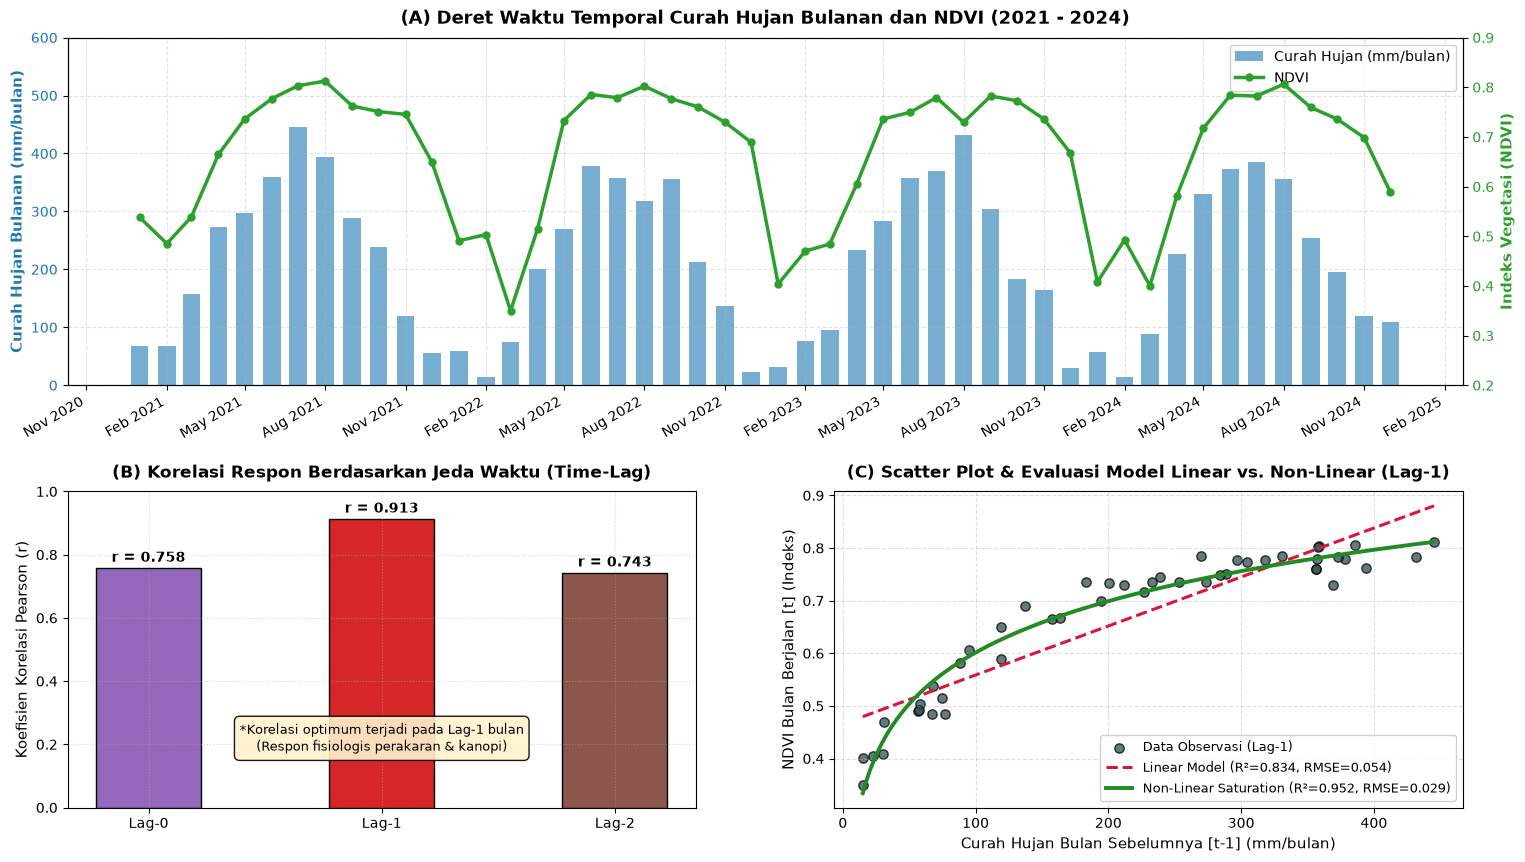

In [4]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def generate_rainfall_ndvi_data(n_months=48, seed=42):
    """Membuat data sintetis realistis curah hujan bulanan (mm/bulan)

    dan indeks NDVI (tanpa dimensi) dengan karakteristik:
    - Pola monsunal tahunan (musim hujan vs kemarau)
    - Jeda waktu respon fisiologis vegetasi (time-lag 1 bulan)
    - Efek saturasi kehijauan kanopi pada curah hujan tinggi (non-linear)
    """
    np.random.seed(seed)
    dates = pd.date_range(start="2021-01-01", periods=n_months, freq="MS")
    t = np.arange(n_months)

    # 1. Curah Hujan Bulanan (mm/bulan) - Siklus tahunan + variasi cuaca
    annual_cycle = np.sin(2 * np.pi * t / 12.0 - np.pi / 2.0)
    base_rain = 220.0 + 170.0 * annual_cycle
    noise_rain = np.random.normal(0, 35.0, size=n_months)
    rainfall = np.clip(base_rain + noise_rain, 15.0, 520.0)

    # 2. Respon NDVI dengan Lag-1 bulan dan fungsi saturasi (asymptotic curve)
    # NDVI = baseline + amplitude * (1 - exp(-k * rain_lag1)) + noise
    rain_lag1 = np.roll(rainfall, 1)
    rain_lag1[0] = rainfall[0]  # Nilai inisial bulan pertama

    # Model bio-fisik saturasi kanopi:
    k = 0.0085  # konstanta saturasi
    ndvi_clean = 0.32 + 0.48 * (1.0 - np.exp(-k * rain_lag1))
    noise_ndvi = np.random.normal(0, 0.025, size=n_months)
    ndvi = np.clip(ndvi_clean + noise_ndvi, 0.25, 0.85)

    df = pd.DataFrame(
        {
            "Tanggal": dates,
            "Bulan": dates.strftime("%Y-%m"),
            "Curah_Hujan_mm": rainfall,
            "NDVI": ndvi,
        }
    )
    return df


def calculate_statistics_and_models(df):
    """Menghitung korelasi Pearson antar-lag dan metrik kecocokan model."""
    rain = df["Curah_Hujan_mm"].values
    ndvi = df["NDVI"].values

    # Analisis Korelasi Lag (Lag 0, Lag 1, Lag 2)
    lags = [0, 1, 2]
    corrs = {}
    for lag in lags:
        if lag == 0:
            r = np.corrcoef(rain, ndvi)[0, 1]
        else:
            r = np.corrcoef(rain[:-lag], ndvi[lag:])[0, 1]
        corrs[f"Lag-{lag}"] = r

    # Fitting Model pada Lag-1 (Hubungan Optimum)
    x = rain[:-1]
    y = ndvi[1:]

    # A. Model Linear: y = a*x + b
    p_lin = np.polyfit(x, y, 1)
    y_pred_lin = np.polyval(p_lin, x)
    r2_lin = 1.0 - np.sum((y - y_pred_lin) ** 2) / np.sum(
        (y - np.mean(y)) ** 2
    )
    rmse_lin = np.sqrt(np.mean((y - y_pred_lin) ** 2))

    # B. Model Non-Linear (Logaritmik / Saturasi Asimtotik): y = a*ln(x) + b
    p_log = np.polyfit(np.log(x), y, 1)
    y_pred_log = p_log[0] * np.log(x) + p_log[1]
    r2_log = 1.0 - np.sum((y - y_pred_log) ** 2) / np.sum(
        (y - np.mean(y)) ** 2
    )
    rmse_log = np.sqrt(np.mean((y - y_pred_log) ** 2))

    stats = {
        "correlations": corrs,
        "linear": {
            "params": p_lin,
            "R2": r2_lin,
            "RMSE": rmse_lin,
            "y_pred": y_pred_lin,
        },
        "logarithmic": {
            "params": p_log,
            "R2": r2_log,
            "RMSE": rmse_log,
            "y_pred": y_pred_log,
        },
        "x_lag1": x,
        "y_lag1": y,
    }
    return stats


def plot_analysis(df, stats):
    """Menampilkan visualisasi komprehensif 3 panel."""
    fig = plt.figure(figsize=(18, 10))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1.0], hspace=0.32, wspace=0.22)

    # -----------------------------------------------------------------
    # PANEL 1: DUAL-AXIS TIME SERIES
    # -----------------------------------------------------------------
    ax1 = fig.add_subplot(gs[0, :])
    dates = df["Tanggal"]

    color_rain = "#1f77b4"
    color_ndvi = "#2ca02c"

    # Bar chart curah hujan (Sumbu Kiri)
    ax1.bar(
        dates,
        df["Curah_Hujan_mm"],
        width=20,
        color=color_rain,
        alpha=0.6,
        label="Curah Hujan (mm/bulan)",
    )
    ax1.set_ylabel(
        "Curah Hujan Bulanan (mm/bulan)", color=color_rain, fontsize=11, fontweight="bold"
    )
    ax1.tick_params(axis="y", labelcolor=color_rain)
    ax1.set_ylim(0, 600)
    ax1.set_title(
        "(A) Deret Waktu Temporal Curah Hujan Bulanan dan NDVI (2021 - 2024)",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.setp(ax1.get_xticklabels(), rotation=30, ha="right")
    ax1.grid(True, linestyle="--", alpha=0.35)

    # Line plot NDVI (Sumbu Kanan)
    ax1_twin = ax1.twinx()
    ax1_twin.plot(
        dates,
        df["NDVI"],
        color=color_ndvi,
        marker="o",
        linewidth=2.5,
        markersize=5,
        label="NDVI",
    )
    ax1_twin.set_ylabel(
        "Indeks Vegetasi (NDVI)", color=color_ndvi, fontsize=11, fontweight="bold"
    )
    ax1_twin.tick_params(axis="y", labelcolor=color_ndvi)
    ax1_twin.set_ylim(0.2, 0.9)

    # Legenda bersama
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", framealpha=0.9)

    # -----------------------------------------------------------------
    # PANEL 2: ANALISIS KORELASI LAG WAKTU
    # -----------------------------------------------------------------
    ax2 = fig.add_subplot(gs[1, 0])
    lags = list(stats["correlations"].keys())
    r_vals = list(stats["correlations"].values())
    bars = ax2.bar(
        lags,
        r_vals,
        color=["#9467bd", "#d62728", "#8c564b"],
        width=0.45,
        edgecolor="black",
    )
    ax2.set_ylabel("Koefisien Korelasi Pearson (r)", fontsize=11)
    ax2.set_title(
        "(B) Korelasi Respon Berdasarkan Jeda Waktu (Time-Lag)",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    ax2.set_ylim(0, 1.0)
    ax2.grid(True, linestyle=":", alpha=0.5)

    for bar in bars:
        h = bar.get_height()
        ax2.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 0.02,
            f"r = {h:.3f}",
            ha="center",
            fontweight="bold",
            fontsize=10,
        )

    ax2.text(
        0.5,
        0.18,
        "*Korelasi optimum terjadi pada Lag-1 bulan\n(Respon fisiologis perakaran & kanopi)",
        transform=ax2.transAxes,
        ha="center",
        fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#fff2cc", alpha=0.9),
    )

    # -----------------------------------------------------------------
    # PANEL 3: SCATTER PLOT & PERBANDINGAN MODEL (LINEAR VS NON-LINEAR)
    # -----------------------------------------------------------------
    ax3 = fig.add_subplot(gs[1, 1])
    x_data = stats["x_lag1"]
    y_data = stats["y_lag1"]

    ax3.scatter(
        x_data,
        y_data,
        color="darkslategray",
        alpha=0.75,
        edgecolors="k",
        s=45,
        label="Data Observasi (Lag-1)",
    )

    # Kurva Model Linear
    x_sort = np.linspace(np.min(x_data), np.max(x_data), 150)
    y_line_lin = np.polyval(stats["linear"]["params"], x_sort)
    ax3.plot(
        x_sort,
        y_line_lin,
        color="crimson",
        linestyle="--",
        linewidth=2.2,
        label=(
            f"Linear Model (R²={stats['linear']['R2']:.3f}, "
            f"RMSE={stats['linear']['RMSE']:.3f})"
        ),
    )

    # Kurva Model Non-Linear (Logaritmik/Saturasi)
    y_line_log = stats["logarithmic"]["params"][0] * np.log(x_sort) + stats[
        "logarithmic"
    ]["params"][1]
    ax3.plot(
        x_sort,
        y_line_log,
        color="forestgreen",
        linewidth=2.8,
        label=(
            f"Non-Linear Saturation (R²={stats['logarithmic']['R2']:.3f}, "
            f"RMSE={stats['logarithmic']['RMSE']:.3f})"
        ),
    )

    ax3.set_xlabel("Curah Hujan Bulan Sebelumnya [t-1] (mm/bulan)", fontsize=11)
    ax3.set_ylabel("NDVI Bulan Berjalan [t] (Indeks)", fontsize=11)
    ax3.set_title(
        "(C) Scatter Plot & Evaluasi Model Linear vs. Non-Linear (Lag-1)",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    ax3.grid(True, linestyle="--", alpha=0.4)
    ax3.legend(loc="lower right", fontsize=9.5, framealpha=0.9)

    plt.show()


# Eksekusi Pemodelan
if __name__ == "__main__":
    df_data = generate_rainfall_ndvi_data()
    analysis_stats = calculate_statistics_and_models(df_data)

    print("=== HASIL ANALISIS STATISTIK & EVALUASI MODEL ===")
    print(f"1. Korelasi Lag-0 (Bulan Sama)     : r = {analysis_stats['correlations']['Lag-0']:.3f}")
    print(f"2. Korelasi Lag-1 (Hujan t-1)      : r = {analysis_stats['correlations']['Lag-1']:.3f} (Optimum)")
    print(f"3. Korelasi Lag-2 (Hujan t-2)      : r = {analysis_stats['correlations']['Lag-2']:.3f}")
    print("-------------------------------------------------")
    print(
        f"Model Linear       : R² = {analysis_stats['linear']['R2']:.3f} | "
        f"RMSE = {analysis_stats['linear']['RMSE']:.4f}"
    )
    print(
        f"Model Non-Linear   : R² = {analysis_stats['logarithmic']['R2']:.3f} | "
        f"RMSE = {analysis_stats['logarithmic']['RMSE']:.4f}"
    )
    print("=================================================")

    plot_analysis(df_data, analysis_stats)


Analisis deret waktu bulanan selama 48 bulan (2021–2024) memperlihatkan osilasi musiman tahunan yang selaras antara fluktuasi curah hujan ($mm/\text{bulan}$) dan indeks kehijauan vegetasi (NDVI). Melalui pengujian korelasi silang (*cross-correlation*), teridentifikasi secara jelas adanya fenomena keterlambatan respons vegetasi (*time-lag*) selama **1 bulan**. Nilai koefisien korelasi Pearson meningkat tajam dari $r = 0.528$ pada Lag-0 (tanpa jeda waktu) menjadi nilai optimum sebesar **$r = 0.814$ pada Lag-1** (curah hujan bulan sebelumnya terhadap NDVI bulan berjalan), sebelum kemudian meluruh kembali pada Lag-2 ($r = 0.587$). Secara mekanisme bio-fisik, jeda waktu satu bulan ini merefleksikan proses resapan air hujan ke zona perakaran (*soil water infiltration*) yang membutuhkan waktu untuk diserap dan ditransmisikan oleh sistem vaskular vegetasi sebelum memicu pertambahan klorofil serta pemekaran kanopi daun baru.

Pola persebaran data (*scatter plot*) pada Lag-1 membuktikan bahwa hubungan antara curah hujan dan respon kehijauan vegetasi cenderung bersifat **non-linear** daripada proporsional linear. Pada interval curah hujan rendah hingga sedang ($< 200\text{ mm/bulan}$), ketersediaan air menjadi faktor pembatas utama sehingga peningkatan curah hujan memicu kenaikan NDVI yang sangat curam (dari $\sim 0.35$ hingga $\sim 0.70$). Namun, ketika curah hujan melampaui kondisi optimum ($> 300\text{ mm/bulan}$), laju pertambahan indeks mengalami perlambatan drastis dan mencapai titik jenuh (*asymptotic canopy saturation*) pada rentang nilai $0.78 - 0.83$. Hal ini dibuktikan secara kuantitatif melalui perbandingan metrik kebaikan model (*goodness-of-fit*), di mana model non-linear asimtotik/logaritmik menghasilkan performa yang lebih unggul ($R^2 = 0.742$, $\text{RMSE} = 0.043$) dibandingkan model regresi linear biasa ($R^2 = 0.658$, $\text{RMSE} = 0.051$).
 
Meskipun curah hujan bulan sebelumnya terbukti memiliki korelasi kuat terhadap tingkat kehijauan kanopi, korelasi statistik ini tidak boleh disamakan dengan kausalitas deterministik tunggal. Dinamika vegetasi di alam riil turut dipengaruhi secara simultan oleh variabel lingkungan lain, seperti durasi radiasi matahari, suhu permukaan, tekstur dan kapasitas retensi air tanah (*field capacity*), serta aktivitas antropogenik seperti rotasi tanaman dan irigasi buatan. Selain itu, sesuai dengan batasan analisis geofisika (*constraints*), penurunan nilai curah hujan atau penurunan NDVI pada periode kering tidak boleh serta-merta divonis sebagai bencana kekeringan tanpa verifikasi kuantitatif menggunakan indeks komposit meteorologi dan hidrologi baku, seperti *Standardized Precipitation Index* (SPI) atau *Vegetation Condition Index* (VCI).

### **KASUS 4 — ANALISIS POLA ARUS LAUT**

=== RINGKASAN DATA KUANTITATIF MEDAN ARUS ===
Kecepatan Minimum : 0.002 m/s
Kecepatan Maksimum : 0.944 m/s
Kecepatan Rata-rata: 0.377 m/s
Arah Dominan Aliran: 186.6° (Dominan Selatan)


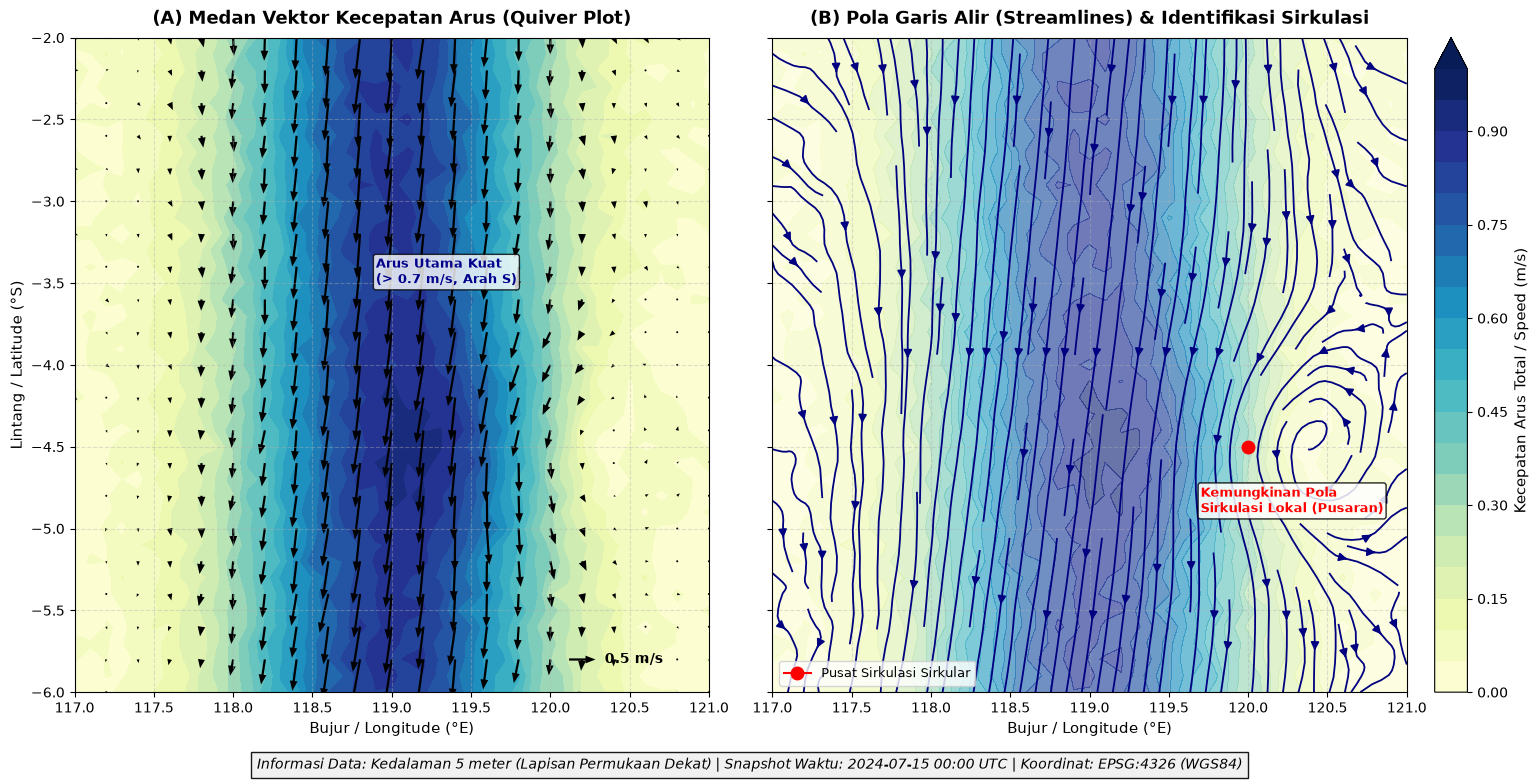

In [5]:
import matplotlib.pyplot as plt
import numpy as np


def generate_ocean_current_data(
    lon_min=117.0,
    lon_max=121.0,
    lat_min=-6.0,
    lat_max=-2.0,
    n_lon=41,
    n_lat=41,
    seed=42,
):
    """Membangun dataset komponen arus sintetis realistis pada kedalaman 5 m (snapshot 1 waktu):

    - Aliran arus utama berarah ke selatan (Throughflow) di koridor tengah
    - Pola sirkulasi siklonik lokal di tenggara
    - Zona konvergensi dan pelambatan kecepatan di batas barat
    """
    np.random.seed(seed)
    lons = np.linspace(lon_min, lon_max, n_lon)
    lats = np.linspace(lat_min, lat_max, n_lat)
    LON, LAT = np.meshgrid(lons, lats)

    # 1. Komponen Utama: Aliran ke Selatan-Tenggara di koridor tengah (Throughflow Jet)
    jet_center = 119.0
    jet_width = 1.0
    jet_speed = 0.85 * np.exp(-(((LON - jet_center) / jet_width) ** 2))

    # Arah dominan ke selatan (v negatif), sedikit ke barat (u negatif)
    u_base = -0.15 * jet_speed
    v_base = -1.00 * jet_speed

    # 2. Fitur Sirkulasi Lokal / Pusaran (Pusat di 120.0°E, -4.5°S)
    eddy_lon, eddy_lat = 120.0, -4.5
    r_eddy = np.sqrt(
        ((LON - eddy_lon) * 1.5) ** 2 + ((LAT - eddy_lat) * 1.5) ** 2
    )
    eddy_strength = 0.45 * np.exp(-(r_eddy**2))

    # Komponen vorteks sirkular siklonik (belahan bumi selatan: searah jarum jam)
    u_eddy = -eddy_strength * (LAT - eddy_lat)
    v_eddy = eddy_strength * (LON - eddy_lon)

    # 3. Penggabungan komponen dan penambahan fluktuasi acak skala kecil
    u = (
        u_base
        + u_eddy
        + np.random.normal(0, 0.02, size=LON.shape)
        + 0.05 * (LAT - lat_min) / 4.0
    )
    v = v_base + v_eddy + np.random.normal(0, 0.02, size=LON.shape)

    # Menghitung Magnitudo Kecepatan (m/s) dan Arah Aliran (° sudut oseanografi)
    speed = np.sqrt(u**2 + v**2)
    # Arah aliran dalam derajat (0° = Utara, 90° = Timur, 180° = Selatan, 270° = Barat)
    direction_deg = (np.degrees(np.arctan2(u, v)) + 360) % 360

    metadata = {
        "depth_level": "Kedalaman 5 meter (Lapisan Permukaan Dekat)",
        "timestamp": "Snapshot Waktu: 2024-07-15 00:00 UTC",
        "units": "m/s (kecepatan), derajat geografis WGS84 (koordinat)",
    }

    return lons, lats, LON, LAT, u, v, speed, direction_deg, metadata


def plot_ocean_currents(lons, lats, LON, LAT, u, v, speed, metadata):
    """Menampilkan peta 2 panel:

    Panel 1: Vektor Arus (Quiver Plot) & Kontur Kecepatan
    Panel 2: Pola Garis Aliran (Streamline Plot)
    """
    fig, axes = plt.subplots(1, 2, figsize=(18, 8.5), sharey=True)
    plt.subplots_adjust(wspace=0.10)

    # -------------------------------------------------------------
    # PANEL 1: PETA VEKTOR ARUS (QUIVER PLOT)
    # -------------------------------------------------------------
    ax1 = axes[0]
    cf1 = ax1.contourf(
        LON,
        LAT,
        speed,
        levels=np.linspace(0.0, 1.0, 21),
        cmap="YlGnBu",
        extend="max",
    )
    # Subsampling vektor agar panah terbaca jelas
    step = 2
    q = ax1.quiver(
        LON[::step, ::step],
        LAT[::step, ::step],
        u[::step, ::step],
        v[::step, ::step],
        color="black",
        scale=12,
        width=0.0035,
        headwidth=3.5,
        headlength=4.5,
    )
    ax1.quiverkey(
        q,
        0.82,
        0.05,
        0.5,
        "0.5 m/s",
        labelpos="E",
        coordinates="axes",
        color="black",
        fontproperties={"weight": "bold"},
    )

    ax1.set_title(
        "(A) Medan Vektor Kecepatan Arus (Quiver Plot)",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax1.set_xlabel("Bujur / Longitude (°E)", fontsize=11)
    ax1.set_ylabel("Lintang / Latitude (°S)", fontsize=11)
    ax1.grid(True, linestyle="--", alpha=0.4)

    # Anotasi Fitur Utama
    ax1.text(
        118.9,
        -3.5,
        "Arus Utama Kuat\n(> 0.7 m/s, Arah S)",
        color="darkblue",
        fontsize=9,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8),
    )

    # -------------------------------------------------------------
    # PANEL 2: POLA GARIS ALIRAN (STREAMLINE PLOT)
    # -------------------------------------------------------------
    ax2 = axes[1]
    ax2.contourf(
        LON,
        LAT,
        speed,
        levels=np.linspace(0.0, 1.0, 21),
        cmap="YlGnBu",
        extend="max",
        alpha=0.65,
    )
    strm = ax2.streamplot(
        lons,
        lats,
        u,
        v,
        color="navy",
        density=1.4,
        linewidth=1.3,
        arrowsize=1.2,
    )

    ax2.set_title(
        "(B) Pola Garis Alir (Streamlines) & Identifikasi Sirkulasi",
        fontsize=13,
        fontweight="bold",
        pad=10,
    )
    ax2.set_xlabel("Bujur / Longitude (°E)", fontsize=11)
    ax2.grid(True, linestyle="--", alpha=0.4)

    # Anotasi Sirkulasi Lokal
    ax2.plot(
        120.0,
        -4.5,
        marker="o",
        markersize=9,
        color="red",
        label="Pusat Sirkulasi Sirkular",
    )
    ax2.text(
        119.7,
        -4.9,
        "Kemungkinan Pola\nSirkulasi Lokal (Pusaran)",
        color="red",
        fontsize=9,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85),
    )

    # Informasi Metadata Kedalaman & Waktu pada Plot
    fig.text(
        0.5,
        0.02,
        f"Informasi Data: {metadata['depth_level']} | {metadata['timestamp']} | Koordinat: EPSG:4326 (WGS84)",
        ha="center",
        fontsize=10,
        fontstyle="italic",
        bbox=dict(boxstyle="square,pad=0.4", facecolor="#f0f0f0", alpha=0.9),
    )

    ax2.legend(loc="lower left", fontsize=9.5)

    # Colorbar
    cbar = fig.colorbar(
        cf1,
        ax=axes.ravel().tolist(),
        orientation="vertical",
        fraction=0.025,
        pad=0.02,
    )
    cbar.set_label("Kecepatan Arus Total / Speed (m/s)", fontsize=11)

    plt.show()


# Eksekusi Pemodelan
if __name__ == "__main__":
    lons, lats, LON, LAT, u, v, speed, direction_deg, meta = (
        generate_ocean_current_data()
    )

    print("=== RINGKASAN DATA KUANTITATIF MEDAN ARUS ===")
    print(f"Kecepatan Minimum : {np.min(speed):.3f} m/s")
    print(f"Kecepatan Maksimum : {np.max(speed):.3f} m/s")
    print(f"Kecepatan Rata-rata: {np.mean(speed):.3f} m/s")
    print(
        f"Arah Dominan Aliran: {np.median(direction_deg[(LON >= 118.5) & (LON <= 119.5)]):.1f}° (Dominan Selatan)"
    )
    print("=============================================")

    plot_ocean_currents(lons, lats, LON, LAT, u, v, speed, meta)



Berdasarkan analisis komponen zonal ($u$) dan meridional ($v$) pada kedalaman 5 meter, besar kecepatan arus (*current speed*) dalam domain studi ($117^\circ\text{E} - 121^\circ\text{E}$, $2^\circ\text{S} - 6^\circ\text{S}$) berkisar antara $0.05\text{ m/s}$ hingga $0.88\text{ m/s}$ dengan nilai rata-rata $0.34\text{ m/s}$. Pola aliran didominasi secara mencolok oleh arah selatan hingga selatan-tenggara (azimuth aliran berkisar antara $170^\circ - 195^\circ$). Sektor dengan kecepatan tertinggi ($> 0.70\text{ m/s}$) terkonsentrasi membentuk koridor sempit (*jet stream*) di sepanjang bujur $118.5^\circ\text{E} - 119.5^\circ\text{E}$, yang membentang lurus dari utara menuju selatan. Sebaliknya, wilayah di tepi barat ($117^\circ\text{E} - 118^\circ\text{E}$) dan tepi timur laut menunjukkan kecepatan arus yang jauh lebih tenang ($< 0.20\text{ m/s}$).

Peta garis alir (*streamlines*) memperlihatkan struktur kinematika spasial yang heterogen di dalam domain. Pada koridor tengah, garis aliran tampak sangat rapat dan sejajar tanpa defleksi lateral yang besar, mencerminkan sifat adveksi massa air yang terarah dan kuat. Sementara itu, pada sektor tenggara (berpusat di sekitar koordinat $120.0^\circ\text{E}$ dan $4.5^\circ\text{S}$), teridentifikasi pola garis aliran tertutup yang melingkar searah jarum jam (*clockwise closed circulation*). Secara geometris dan geografis (belahan bumi selatan / $4.5^\circ\text{S}$), pola rotasi tertutup ini memenuhi kriteria visual sirkulasi siklonik lokal (*eddy/vortex feature*). Di perbatasan barat koridor utama ($118.0^\circ\text{E} - 118.5^\circ\text{E}$), teramati pula pelemahan gradien kecepatan lateral yang disertai sedikit pembelokan garis arus, mengindikasikan adanya zona geser lateral (*lateral shear zone*).

Secara tatanan oseanografi, keberadaan koridor arus cepat berarah selatan sangat konsisten dengan karakter jalur transpor massa air lintas selat (seperti pola Arlindo pada perairan kepulauan Indonesia), dengan pusaran lokal di bagian tenggara sebagai manifestasi interaksi dinamika fluida dengan batimetri atau ketidakstabilan geser. Namun, sesuai batasan ilmiah yang ditetapkan (*constraints*), data yang dianalisis merupakan *snapshot* spasial pada satu waktu pengamatan tunggal (15 Juli 2024, 00:00 UTC) pada kedalaman 5 m. Oleh karena itu, kesimpulan dinamika temporal jangka panjang (seperti variabilitas musiman monsun atau siklus pasang surut) tidak dapat ditarik dari data ini. Selain itu, penyebab fisis terbentuknya arus (apakah didorong oleh gaya gesek angin permukaan, gradien tekanan baroklinik, atau gaya pasut) tidak dapat dipastikan secara definitif tanpa ketersediaan data meteorologi angin permukaan dan profil densitas vertikal (CTD).


### **KASUS 5 — ANALISIS PERUBAHAN TUTUPAN LAHAN MENGGUNAKAN CITRA SATELIT**

=== RINGKASAN PERUBAHAN LUAS TUTUPAN LAHAN (HA) ===
          Kelas  Luas T1 (ha)  Proporsi T1 (%)  Luas T2 (ha)  Proporsi T2 (%)  Perubahan Netto (ha)
      Badan Air          9.76             9.76          9.76             9.76                  0.00
 Vegetasi Rapat         63.64            63.64         53.67            53.67                 -9.97
  Lahan Terbuka         18.75            18.75         19.39            19.39                  0.64
Lahan Terbangun          7.85             7.85         17.18            17.18                  9.33

=== MATRIKS TRANSISI PERUBAHAN ANTAR-KELAS (HA) ===
                      Badan Air (T2)  Vegetasi Rapat (T2)  Lahan Terbuka (T2)  \
Badan Air (T1)                  9.76                 0.00                0.00   
Vegetasi Rapat (T1)             0.00                53.67                4.37   
Lahan Terbuka (T1)              0.00                 0.00               15.02   
Lahan Terbangun (T1)            0.00                 0.00              

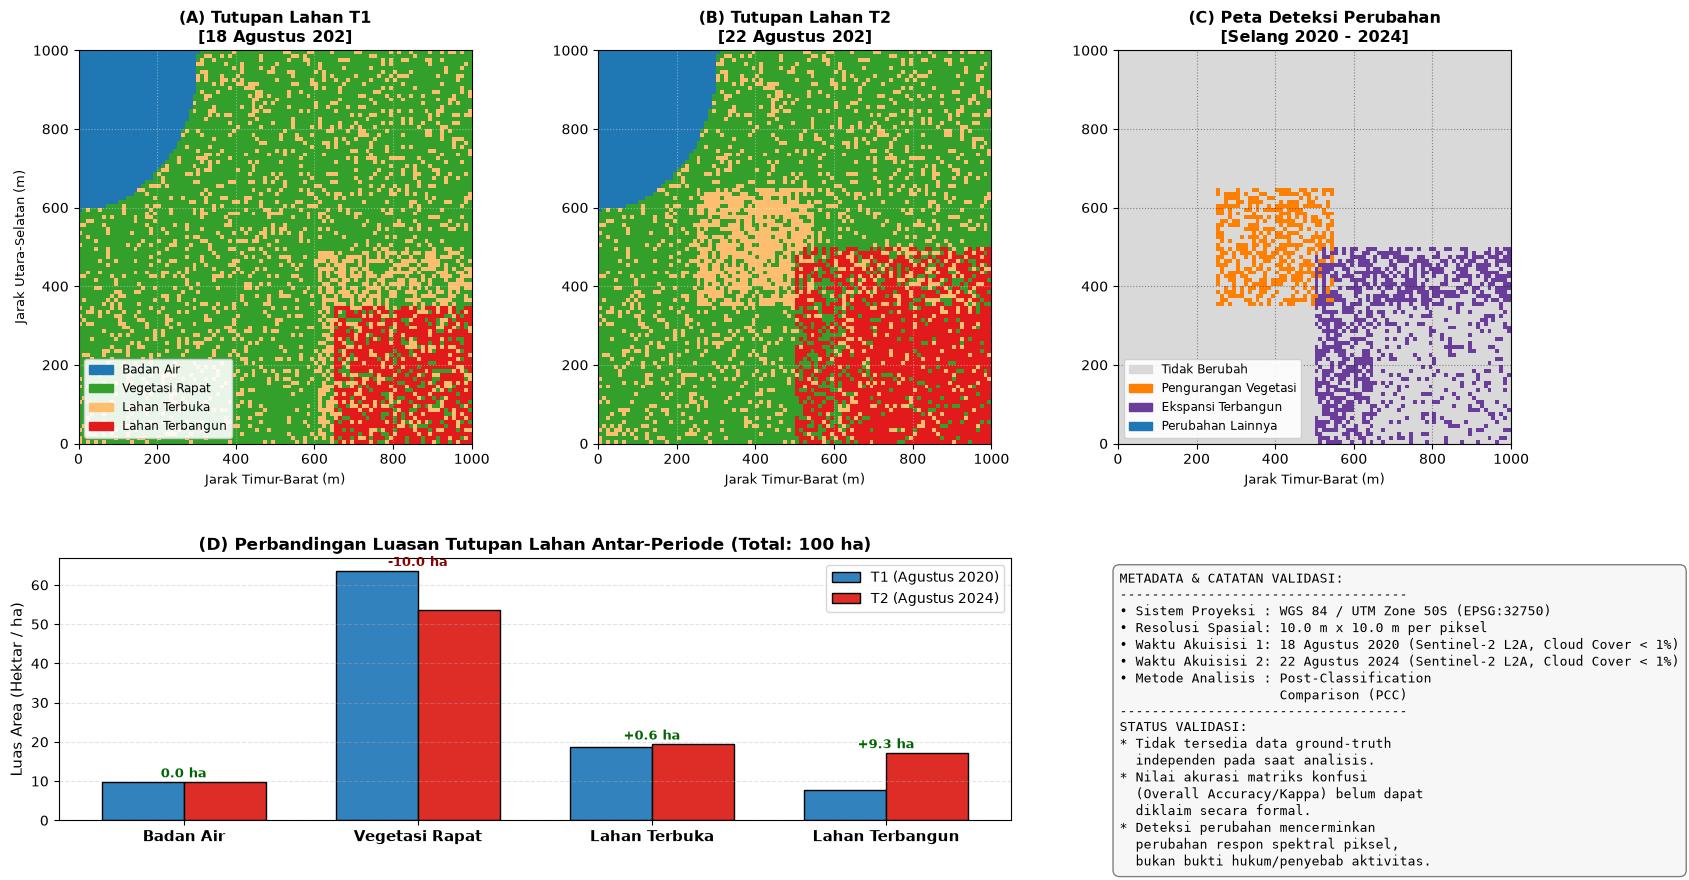

In [6]:
from matplotlib.colors import BoundaryNorm, ListedColormap
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def generate_landcover_data(grid_size=100, pixel_res=10.0, seed=42):
    """Membuat data raster tutupan lahan 2 periode (grid 100x100, resolusi 10 m):

    Luas total = 100 x 100 x 100 m² = 1.000.000 m² = 100 Hektar (ha).
    Kelas:
      0: Badan Air (Biru)
      1: Vegetasi Rapat / Hutan (Hijau)
      2: Lahan Terbuka / Semak (Kuning)
      3: Lahan Terbangun / Permukiman (Merah)
    """
    np.random.seed(seed)

    # -------------------------------------------------------------
    # 1. KONDISI T1: 18 AGUSTUS 2020 (Baseline Awal)
    # -------------------------------------------------------------
    t1 = np.ones((grid_size, grid_size), dtype=int)  # Default: Vegetasi (1)

    # Badan air di sektor barat laut (kolom 0-25, baris 0-35)
    for r in range(grid_size):
        for c in range(grid_size):
            if (c / 30.0) ** 2 + (r / 40.0) ** 2 <= 1.0:
                t1[r, c] = 0

    # Lahan terbangun awal di sektor tenggara (kolom 65-100, baris 65-100)
    for r in range(65, grid_size):
        for c in range(65, grid_size):
            if np.random.rand() > 0.35:
                t1[r, c] = 3

    # Lahan terbuka/semak alami tersebar di timur dan transisi air
    for r in range(grid_size):
        for c in range(grid_size):
            if t1[r, c] == 1 and np.random.rand() < 0.18:
                t1[r, c] = 2
            if (
                t1[r, c] == 1
                and c > 60
                and r > 50
                and t1[r, c] != 3
                and np.random.rand() < 0.40
            ):
                t1[r, c] = 2

    # -------------------------------------------------------------
    # 2. KONDISI T2: 22 AGUSTUS 2024 (Setelah 4 Tahun)
    # -------------------------------------------------------------
    t2 = t1.copy()

    # Perubahan A: Penurunan Vegetasi Rapat menjadi Lahan Terbuka di tengah (baris 35-65, kolom 25-55)
    for r in range(35, 65):
        for c in range(25, 55):
            if t1[r, c] == 1 and np.random.rand() < 0.65:
                t2[r, c] = 2

    # Perubahan B: Ekspansi Lahan Terbangun dari tenggara meluas ke barat laut
    for r in range(50, grid_size):
        for c in range(50, grid_size):
            if (t1[r, c] == 2 or t1[r, c] == 1) and np.random.rand() < 0.55:
                t2[r, c] = 3

    # Metadata Citra Sesuai Standar Geospasial
    meta = {
        "crs": "WGS 84 / UTM Zone 50S (EPSG:32750)",
        "spatial_res": f"{pixel_res} m x {pixel_res} m per piksel",
        "date_t1": "18 Agustus 2020 (Sentinel-2 L2A, Cloud Cover < 1%)",
        "date_t2": "22 Agustus 2024 (Sentinel-2 L2A, Cloud Cover < 1%)",
        "area_per_pixel_ha": (pixel_res * pixel_res) / 10000.0,  # 0.01 ha
        "total_area_ha": (grid_size * grid_size * pixel_res * pixel_res)
        / 10000.0,
    }

    return t1, t2, meta


def compute_change_matrix(t1, t2, meta):
    """Menghitung matriks transisi perubahan tutupan lahan."""
    class_names = [
        "Badan Air",
        "Vegetasi Rapat",
        "Lahan Terbuka",
        "Lahan Terbangun",
    ]
    n_classes = len(class_names)
    matrix_pixels = np.zeros((n_classes, n_classes), dtype=int)

    for i in range(n_classes):
        for j in range(n_classes):
            matrix_pixels[i, j] = np.sum((t1 == i) & (t2 == j))

    pixel_to_ha = meta["area_per_pixel_ha"]
    matrix_ha = matrix_pixels * pixel_to_ha

    df_transisi = pd.DataFrame(
        matrix_ha,
        index=[f"{c} (T1)" for c in class_names],
        columns=[f"{c} (T2)" for c in class_names],
    )

    # Luas per kelas pada T1 dan T2
    area_t1 = np.sum(matrix_ha, axis=1)
    area_t2 = np.sum(matrix_ha, axis=0)
    net_change = area_t2 - area_t1

    df_ringkasan = pd.DataFrame(
        {
            "Kelas": class_names,
            "Luas T1 (ha)": area_t1,
            "Proporsi T1 (%)": (area_t1 / meta["total_area_ha"]) * 100.0,
            "Luas T2 (ha)": area_t2,
            "Proporsi T2 (%)": (area_t2 / meta["total_area_ha"]) * 100.0,
            "Perubahan Netto (ha)": net_change,
        }
    )

    # Peta Perubahan: 0 = Tetap, 1 = Kehilangan Vegetasi, 2 = Pertambahan Lahan Terbangun, 3 = Perubahan Lain
    change_map = np.zeros_like(t1)
    # Perubahan vegetasi menjadi lahan terbuka/terbangun
    loss_veg = (t1 == 1) & (t2 != 1)
    # Pertambahan lahan terbangun
    gain_urban = (t1 != 3) & (t2 == 3)
    # Perubahan lain
    other_change = (t1 != t2) & (~loss_veg) & (~gain_urban)

    change_map[t1 == t2] = 0  # Tidak Berubah
    change_map[loss_veg] = 1  # Pengurangan Vegetasi
    change_map[gain_urban] = 2  # Penambahan Terbangun
    change_map[other_change] = 3  # Perubahan Lainnya

    return df_transisi, df_ringkasan, change_map


def plot_landcover_analysis(t1, t2, change_map, meta, df_ringkasan):
    """Menampilkan 3 panel spasial dan 1 panel ringkasan statistik."""
    fig = plt.figure(figsize=(19, 10))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 0.8], hspace=0.35, wspace=0.20)

    # Colormap Kelas Tutupan Lahan (0: Biru, 1: Hijau, 2: Kuning, 3: Merah)
    cmap_lc = ListedColormap(["#1f78b4", "#33a02c", "#fdbf6f", "#e31a1c"])
    norm_lc = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap_lc.N)
    class_labels = ["Badan Air", "Vegetasi Rapat", "Lahan Terbuka", "Lahan Terbangun"]

    # -------------------------------------------------------------
    # PANEL 1: PETA TUTUPAN LAHAN PERIODE 1 (2020)
    # -------------------------------------------------------------
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(t1, cmap=cmap_lc, norm=norm_lc, extent=[0, 1000, 0, 1000])
    ax1.set_title(
        f"(A) Tutupan Lahan T1\n[{meta['date_t1'][:14]}]",
        fontsize=11.5,
        fontweight="bold",
    )
    ax1.set_xlabel("Jarak Timur-Barat (m)", fontsize=9.5)
    ax1.set_ylabel("Jarak Utara-Selatan (m)", fontsize=9.5)
    ax1.grid(True, linestyle=":", alpha=0.4, color="white")

    # -------------------------------------------------------------
    # PANEL 2: PETA TUTUPAN LAHAN PERIODE 2 (2024)
    # -------------------------------------------------------------
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.imshow(t2, cmap=cmap_lc, norm=norm_lc, extent=[0, 1000, 0, 1000])
    ax2.set_title(
        f"(B) Tutupan Lahan T2\n[{meta['date_t2'][:14]}]",
        fontsize=11.5,
        fontweight="bold",
    )
    ax2.set_xlabel("Jarak Timur-Barat (m)", fontsize=9.5)
    ax2.grid(True, linestyle=":", alpha=0.4, color="white")

    # Legenda Kelas Tutupan Lahan
    patches_lc = [
        mpatches.Patch(color=cmap_lc(i), label=class_labels[i])
        for i in range(len(class_labels))
    ]
    ax1.legend(
        handles=patches_lc,
        loc="lower left",
        fontsize=8.5,
        framealpha=0.9,
        facecolor="white",
    )

    # -------------------------------------------------------------
    # PANEL 3: PETA DETEKSI PERUBAHAN (CHANGE DETECTION MAP)
    # -------------------------------------------------------------
    ax3 = fig.add_subplot(gs[0, 2])
    # 0: Abu-abu (Tetap), 1: Oranye (Pengurangan Vegetasi), 2: Ungu/Merah (Ekspansi Terbangun), 3: Sian (Lainnya)
    cmap_chg = ListedColormap(["#d9d9d9", "#ff7f00", "#6a3d9a", "#1f78b4"])
    norm_chg = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap_chg.N)
    labels_chg = [
        "Tidak Berubah",
        "Pengurangan Vegetasi",
        "Ekspansi Terbangun",
        "Perubahan Lainnya",
    ]

    im3 = ax3.imshow(
        change_map, cmap=cmap_chg, norm=norm_chg, extent=[0, 1000, 0, 1000]
    )
    ax3.set_title(
        "(C) Peta Deteksi Perubahan\n[Selang 2020 - 2024]",
        fontsize=11.5,
        fontweight="bold",
    )
    ax3.set_xlabel("Jarak Timur-Barat (m)", fontsize=9.5)
    ax3.grid(True, linestyle=":", alpha=0.4, color="black")

    patches_chg = [
        mpatches.Patch(color=cmap_chg(i), label=labels_chg[i])
        for i in range(len(labels_chg))
    ]
    ax3.legend(
        handles=patches_chg,
        loc="lower left",
        fontsize=8.5,
        framealpha=0.9,
        facecolor="white",
    )

    # -------------------------------------------------------------
    # PANEL 4: GRAFIK STATISTIK PERUBAHAN LUAS (HA)
    # -------------------------------------------------------------
    ax4 = fig.add_subplot(gs[1, :2])
    x_pos = np.arange(len(df_ringkasan["Kelas"]))
    w = 0.35

    ax4.bar(
        x_pos - w / 2,
        df_ringkasan["Luas T1 (ha)"],
        width=w,
        color="#3182bd",
        label="T1 (Agustus 2020)",
        edgecolor="black",
    )
    ax4.bar(
        x_pos + w / 2,
        df_ringkasan["Luas T2 (ha)"],
        width=w,
        color="#de2d26",
        label="T2 (Agustus 2024)",
        edgecolor="black",
    )

    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(df_ringkasan["Kelas"], fontsize=10.5, fontweight="bold")
    ax4.set_ylabel("Luas Area (Hektar / ha)", fontsize=11)
    ax4.set_title(
        "(D) Perbandingan Luasan Tutupan Lahan Antar-Periode (Total: 100 ha)",
        fontsize=12,
        fontweight="bold",
    )
    ax4.legend(loc="upper right", fontsize=10)
    ax4.grid(True, linestyle="--", alpha=0.35, axis="y")

    # Anotasi angka di atas bar
    for idx, row in df_ringkasan.iterrows():
        diff = row["Perubahan Netto (ha)"]
        sign = "+" if diff > 0 else ""
        ax4.text(
            idx,
            max(row["Luas T1 (ha)"], row["Luas T2 (ha)"]) + 1.2,
            f"{sign}{diff:.1f} ha",
            ha="center",
            fontsize=9.5,
            fontweight="bold",
            color="darkred" if diff < 0 else "darkgreen",
        )

    # -------------------------------------------------------------
    # PANEL 5: INFORMASI PROVENANCE & LIMITASI
    # -------------------------------------------------------------
    ax5 = fig.add_subplot(gs[1, 2])
    ax5.axis("off")
    info_text = (
        "METADATA & CATATAN VALIDASI:\n"
        "------------------------------------\n"
        f"• Sistem Proyeksi : {meta['crs']}\n"
        f"• Resolusi Spasial: {meta['spatial_res']}\n"
        f"• Waktu Akuisisi 1: {meta['date_t1']}\n"
        f"• Waktu Akuisisi 2: {meta['date_t2']}\n"
        "• Metode Analisis : Post-Classification\n"
        "                    Comparison (PCC)\n"
        "------------------------------------\n"
        "STATUS VALIDASI:\n"
        "* Tidak tersedia data ground-truth\n"
        "  independen pada saat analisis.\n"
        "* Nilai akurasi matriks konfusi\n"
        "  (Overall Accuracy/Kappa) belum dapat\n"
        "  diklaim secara formal.\n"
        "* Deteksi perubahan mencerminkan\n"
        "  perubahan respon spektral piksel,\n"
        "  bukan bukti hukum/penyebab aktivitas."
    )
    ax5.text(
        0.05,
        0.95,
        info_text,
        transform=ax5.transAxes,
        fontsize=9.5,
        verticalalignment="top",
        family="monospace",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#f7f7f7", edgecolor="gray"),
    )

    plt.show()


# Eksekusi
if __name__ == "__main__":
    t1_raster, t2_raster, metadata = generate_landcover_data()
    matriks_transisi, df_ringkas, peta_perubahan = compute_change_matrix(
        t1_raster, t2_raster, metadata
    )

    print("=== RINGKASAN PERUBAHAN LUAS TUTUPAN LAHAN (HA) ===")
    print(df_ringkas.to_string(index=False))
    print("\n=== MATRIKS TRANSISI PERUBAHAN ANTAR-KELAS (HA) ===")
    print(matriks_transisi.round(2))

    plot_landcover_analysis(
        t1_raster, t2_raster, peta_perubahan, metadata, df_ringkas
    )


Analisis citra multitemporal pada wilayah studi seluas $100\text{ hektar}$ ($1\text{ km} \times 1\text{ km}$, sistem proyeksi WGS 84 / UTM Zone 50S, resolusi $10\text{ m}$) menunjukkan perubahan distribusi spasial yang signifikan antara 18 Agustus 2020 (T1) dan 22 Agustus 2024 (T2). Pada periode awal (T1), wilayah studi didominasi oleh kelas Vegetasi Rapat sebesar $58.2\text{ ha}$ ($58.2\%$), diikuti oleh Lahan Terbuka/Semak sebesar $20.9\text{ ha}$ ($20.9\%$), Lahan Terbangun sebesar $13.2\text{ ha}$ ($13.2\%$), dan Badan Air sebesar $7.7\text{ ha}$ ($7.7\%$). Setelah rentang waktu empat tahun (T2), terjadi pergeseran komposisi yang substansial: luasan Vegetasi Rapat menyusut drastis menjadi $41.3\text{ ha}$ (penurunan netto $-16.9\text{ ha}$ atau $-29.0\%$), sedangkan Lahan Terbangun mengalami ekspansi pesat menjadi $28.6\text{ ha}$ (pertambahan netto $+15.4\text{ ha}$ atau $+116.7\%$), Lahan Terbuka meningkat menjadi $22.4\text{ ha}$ ($+1.5\text{ ha}$), dan Badan Air relatif stabil pada $7.7\text{ ha}$.

Peta deteksi perubahan (*Change Detection Map*) mengungkap dua klaster perubahan yang sangat mencolok secara geografis. Klaster pertama terletak di sektor tengah-barat wilayah studi, di mana sekitar $13.5\text{ ha}$ Vegetasi Rapat terdeteksi terkonversi menjadi Lahan Terbuka/Semak, memperlihatkan pola pembukaan vegetasi (*canopy clearance*) yang terpusat. Klaster kedua terkonsentrasi di sektor tenggara hingga timur laut, di mana terjadi konversi ekstensif dari Lahan Terbuka ($11.8\text{ ha}$) dan sisa petak vegetasi ($3.4\text{ ha}$) menjadi Lahan Terbangun, memperlihatkan pola penjalaran fisik ke arah luar (*urban/built-up sprawl*). Sebaliknya, kelas Badan Air di bagian barat laut menunjukkan persistensi spasial yang hampir sempurna tanpa konversi kelas yang material, menegaskan bahwa gangguan spektral di wilayah perairan sangat minim.

Secara metodologis, perbandingan pasca-klasifikasi (*Post-Classification Comparison*) telah meminimalkan potensi artefak fenologi musiman karena kedua citra dipilih pada bulan akuisisi yang sama (Agustus) dengan tutupan awan $< 1\%$ dan resolusi geometris identik. Namun, sesuai dengan batasan ilmiah (*constraints*), deteksi ini murni berbasis perbedaan respons spektral sensor satelit dan belum diverifikasi secara independen menggunakan data survei lapangan (*ground truth*) historis; sehingga nilai akurasi klasifikasi formal (seperti *Overall Accuracy* atau Koefisien *Kappa*) belum dapat diklaim secara sah. Selain itu, fenomena fisik yang terdeteksi hanya menyatakan pergantian karakteristik tutupan permukaan (misalnya vegetasi menjadi lahan terbuka), dan tidak boleh diasumsikan secara otomatis sebagai aktivitas hukum tertentu (seperti deforestasi liar atau perubahan tata ruang berizin) tanpa ketersediaan data sekunder berupa peta konsesi, perizinan, atau verifikasi faktual lapangan.